# ViGoEmotions Final: RQ1 analysis (threshold decoding)

**RQ1.** Is a single uniform decision threshold (τ = 0.5) optimal across all emotion labels in the presence of severe
class imbalance?

**Hypothesis (midterm slide 9).** Per-label thresholds help tail labels most, but over-fit most there too.

This notebook answers RQ1 with the **midterm PhoBERT-base-v2** (the best neural model of the midterm). It only reads the
PhoBERT probabilities saved by `01_Midterm_Baselines.ipynb` in
`code/results/predictions/midterm_phobert_{val,test}.csv`, so the backbone is **not retrained** and no GPU is needed.

| Strategy | Rule | Fitted on |
|---|---|---|
| `fixed` | p ≥ 0.5 for every label | nothing |
| `global` | p ≥ τ\*, τ\* = argmax Macro-F1 on validation | validation |
| `per_label` | p ≥ τc\*, τc\* = argmax F1 of label c on validation | validation |

All thresholds are searched on the grid 0.05, 0.06, …, 0.95, **frozen**,
saved to `thresholds.json`, and only then applied to test. Tiers (head / mid / tail) are the midterm tiers, fixed from
train counts before any evaluation.

**Paths.** Every path is relative to the submission's `code/` folder, found automatically: locally, start Jupyter
in `code/notebooks/`; on Colab, upload the unzipped submission folder anywhere in *My Drive* and open the notebook
from there (the setup cell mounts Drive and finds `62FIT4ATI-CLC02_G02_P02/code`). If `code/data/` is empty, the
dataset is downloaded from the authors' GitHub repository and checked against `code/splits/`.

**Outputs** (all under `code/results/`):
* `predictions/rq1_predictions_val.csv`, `predictions/rq1_predictions_test.csv`, `predictions/rq1_predictions.npz`:
  the prediction file required by the brief;
* `rq1_thresholds.json`, `rq1_summary.json`, and `tables/rq1_*.csv`: one CSV per result table;
* `figures/rq1_*.png`: every figure, for the report;
* `tables/rq1_audit_*.csv`: the error-audit samples, with empty `error_type` and `notes` columns to fill in by hand.

**License.** Comment text is printed and saved only when `SHOW_COMMENT_TEXT = True`. Keep it `False` in any shared
copy, and never commit an audit CSV that contains text.

## 1. Setup

In [2]:
import ast, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score, hamming_loss, label_ranking_average_precision_score

import os
import urllib.request
from pathlib import Path

PREFIX = '62FIT4ATI-CLC02_G02_P02'
DATA_URL = 'https://raw.githubusercontent.com/ricardo-tran/ViGoEmotions/main/corpus/'   # official dataset repo
DATA_FILES = ['train.csv', 'val.csv', 'test.csv', 'label_dict.json']


def find_code_dir():
    """The submission's code/ folder (the one holding notebooks/ and splits/)."""
    here = Path.cwd().resolve()
    for p in (here, here.parent):                     # local Jupyter started in code/notebooks/ or code/
        if (p / 'notebooks').is_dir() and (p / 'splits').is_dir():
            return p
    try:                                              # Colab: the notebook was opened from Google Drive
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError('Start Jupyter from the code/notebooks/ folder of the submission.')
    drive.mount('/content/drive')
    for depth in range(5):                            # search MyDrive up to 4 folders deep
        hits = sorted(Path('/content/drive/MyDrive').glob('*/' * depth + f'{PREFIX}/code'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'{PREFIX}/code not found in MyDrive; upload the unzipped submission folder there.')


CODE_DIR = find_code_dir()
CORPUS_DIR = CODE_DIR / 'data'            # dataset, downloaded here if missing (licence: never redistributed or submitted)
CORPUS_DIR.mkdir(exist_ok=True)
for f in DATA_FILES:
    if not (CORPUS_DIR / f).exists():
        print('Downloading', f)
        urllib.request.urlretrieve(DATA_URL + f, CORPUS_DIR / f)
print('Code dir: .../' + '/'.join(CODE_DIR.parts[-2:]))

OUT_DIR = CODE_DIR / 'results'                           # rq1_thresholds.json, rq1_summary.json
TABLE_DIR, PRED_DIR, FIG_DIR = OUT_DIR / 'tables', OUT_DIR / 'predictions', OUT_DIR / 'figures'
PROBS_CSV = PRED_DIR / 'midterm_phobert_{}.csv'          # midterm PhoBERT probabilities (read only)

SEED = 42
SHOW_COMMENT_TEXT = False      # True: show and save comment text in the audit (local inspection only)
N_AUDIT = 20                   # false negatives and false positives sampled for the audit
N_BOOT = 1000                  # paired bootstrap resamples
TAUS = np.round(np.arange(0.05, 0.951, 0.01), 2)
STRATEGIES = ['fixed', 'global', 'per_label']
SPLITS = ['train', 'val', 'test']

assert Path(str(PROBS_CSV).format('test')).exists(), 'Run 01_Midterm_Baselines.ipynb first (midterm_phobert_*.csv)'
for d in (TABLE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold', 'font.size': 9.5})
TIER_COLORS = {'head': '#2a78d6', 'mid': '#eb6834', 'tail': '#1baf7a'}
STRAT_COLORS = {'fixed': '#9a9893', 'global': '#2a78d6', 'per_label': '#eb6834'}


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f'rq1_{name}.png', dpi=200, bbox_inches='tight')
    plt.show()


def save_table(df, name):
    df.to_csv(TABLE_DIR / f'rq1_{name}.csv')
    display(df.round(4))

Mounted at /content/drive
Code dir: .../62FIT4ATI-CLC02_G02_P02/code


## 2. Data, tiers and saved probabilities

In [3]:
with open(CORPUS_DIR / 'label_dict.json', encoding='utf-8') as f:
    label_dict = {int(k): v for k, v in json.load(f).items()}
LABELS = [label_dict[i] for i in range(len(label_dict))]
N_LABELS = len(LABELS)
assert N_LABELS == 28 and LABELS[27] == 'neutral'


def to_multihot(idx_list):
    y = np.zeros(N_LABELS, dtype=np.int8)
    y[idx_list] = 1
    return y


dfs, Y = {}, {}
for s in SPLITS:
    df = pd.read_csv(CORPUS_DIR / f'{s}.csv', dtype={'id': str})
    df['label_idx'] = df['labels'].apply(ast.literal_eval)
    dfs[s] = df
    Y[s] = np.stack(df['label_idx'].apply(to_multihot).to_numpy())

for s in SPLITS:                          # the official split must match the submitted split files
    ids = (CODE_DIR / 'splits' / f'{s}_ids.txt').read_text(encoding='utf-8').split()
    assert ids == list(dfs[s]['id']), f'{s}.csv does not match splits/{s}_ids.txt'
print({s: len(dfs[s]) for s in SPLITS})

# Midterm tiers: rank the 28 labels by train count and cut the ranking into 9 / 10 / 9.
train_count = Y['train'].sum(0)
ranked = [LABELS[i] for i in np.argsort(-train_count, kind='stable')]
TIERS = {'head': ranked[:9], 'mid': ranked[9:19], 'tail': ranked[19:]}
TIER_OF = {lab: t for t, labs in TIERS.items() for lab in labs}
TIER_IDX = {t: np.array([LABELS.index(l) for l in labs]) for t, labs in TIERS.items()}
for t, labs in TIERS.items():
    print(f'{t:<5s} ({len(labs)}): ' + ', '.join(labs))

P = {}
for split in ('val', 'test'):
    pr = pd.read_csv(str(PROBS_CSV).format(split), dtype={'sample_id': str})
    assert list(pr['sample_id']) == list(dfs[split]['id']), f'midterm_phobert_{split}.csv ids do not match the corpus'
    P[split] = np.array(pr['probability_vector'].apply(json.loads).tolist(), dtype=float)
print('Probabilities:', {s: P[s].shape for s in P})

{'train': 16531, 'val': 2066, 'test': 2067}
head  (9): amusement, sadness, annoyance, joy, anger, disappointment, disgust, love, caring
mid   (10): optimism, disapproval, approval, embarrassment, admiration, curiosity, excitement, neutral, pride, gratitude
tail  (9): desire, grief, fear, nervousness, remorse, realization, confusion, surprise, relief
Probabilities: {'val': (2066, 28), 'test': (2067, 28)}


## 3. Fit the three strategies on validation, freeze, apply to test

Ties in the grid search go to the lowest threshold (`argmax` keeps the first maximum).

In [4]:
def label_f1(y, pred):
    y, pred = y.astype(bool), pred.astype(bool)
    tp = (y & pred).sum(0); fp = pred.sum(0) - tp; fn = y.sum(0) - tp
    d = 2 * tp + fp + fn
    return np.divide(2 * tp, d, out=np.zeros(y.shape[1]), where=d > 0)


def micro_f1(y, pred):
    tp = (y.astype(bool) & pred.astype(bool)).sum()
    return 2 * tp / (y.sum() + pred.sum())


curves = np.stack([label_f1(Y['val'], P['val'] >= t) for t in TAUS])     # (n_taus, 28) validation F1
THR = {'fixed': np.full(N_LABELS, 0.5),
       'global': np.full(N_LABELS, TAUS[curves.mean(1).argmax()]),
       'per_label': TAUS[curves.argmax(0)]}

(OUT_DIR / 'rq1_thresholds.json').write_text(json.dumps(
    {s: dict(zip(LABELS, map(float, THR[s]))) for s in STRATEGIES}, indent=2))
print(f"Global τ* = {THR['global'][0]:.2f} | per-label τc* from {THR['per_label'].min():.2f} "
      f"to {THR['per_label'].max():.2f}. Thresholds frozen in results/rq1_thresholds.json")

PRED = {s: {split: (P[split] >= THR[s]).astype(np.int8) for split in ('val', 'test')} for s in STRATEGIES}

Global τ* = 0.31 | per-label τc* from 0.14 to 0.64. Thresholds frozen in results/rq1_thresholds.json


## 4. Prediction files required by the brief

One row per comment: `sample_id, true_label_vector, probability_vector, pred_fixed, pred_global, pred_per_label,
label_cardinality`. Vectors are JSON lists of 28 values in label-index order (`label_dict.json`). The same arrays are
in `predictions.npz`. No comment text is written.

In [5]:
def as_json(rows):
    return [json.dumps(r) for r in rows.tolist()]


npz = {}
for split in ('val', 'test'):
    out = pd.DataFrame({'sample_id': dfs[split]['id'],
                        'true_label_vector': as_json(Y[split]),
                        'probability_vector': as_json(np.round(P[split], 6)),
                        **{f'pred_{s}': as_json(PRED[s][split]) for s in STRATEGIES},
                        'label_cardinality': Y[split].sum(1)})
    out.to_csv(PRED_DIR / f'rq1_predictions_{split}.csv', index=False)
    npz.update({f'{split}_sample_id': dfs[split]['id'].to_numpy(str), f'{split}_true': Y[split],
                f'{split}_prob': P[split], f'{split}_cardinality': Y[split].sum(1),
                **{f'{split}_pred_{s}': PRED[s][split] for s in STRATEGIES}})
np.savez_compressed(PRED_DIR / 'rq1_predictions.npz', labels=np.array(LABELS), **npz)

check = pd.read_csv(PRED_DIR / 'rq1_predictions_test.csv', dtype={'sample_id': str})
assert (np.array(check['pred_per_label'].apply(json.loads).tolist()) == PRED['per_label']['test']).all()
display(check.head(3))
print('Saved rq1_predictions_val.csv, rq1_predictions_test.csv and rq1_predictions.npz to results/predictions/')

,sample_id,true_label_vector,probability_vector,pred_fixed,pred_global,pred_per_label,label_cardinality
0,14132,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0.01634, 0.021328, 0.004486, 0.004007, 0.1996...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1
1,3722,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0.955981, 0.273574, 0.379723, 0.00483, 0.0212...","[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1
2,18932,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0.096706, 0.31732, 0.574753, 0.01653, 0.01584...","[0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, ...","[0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1


Saved rq1_predictions_val.csv, rq1_predictions_test.csv and rq1_predictions.npz to results/predictions/


## 5. Main results: Macro-F1, Micro-F1, Hamming loss

LRAP and mAP use probabilities only, so they are the same for every strategy. ΔF1 = F1(val) − F1(test). Because
validation and test differ even with no tuning, the column **excess gap** = ΔF1(strategy) − ΔF1(fixed) isolates
the optimism added by fitting thresholds on validation.

In [6]:
rows = []
for s in STRATEGIES:
    for split in ('val', 'test'):
        y, pred, p = Y[split], PRED[s][split], P[split]
        rows.append({'strategy': s, 'split': split, 'macro_f1': label_f1(y, pred).mean(),
                     'micro_f1': micro_f1(y, pred), 'hamming_loss': hamming_loss(y, pred),
                     'lrap': label_ranking_average_precision_score(y, p),
                     'mAP': average_precision_score(y, p, average='macro'),
                     'mean_pred_labels': pred.sum(1).mean(), 'pct_no_label': 100 * (pred.sum(1) == 0).mean()})
main = pd.DataFrame(rows).set_index(['strategy', 'split'])
print(f"Gold mean labels per comment: val {Y['val'].sum(1).mean():.2f}, test {Y['test'].sum(1).mean():.2f}")
save_table(main, 'table_main_metrics')

gap = pd.DataFrame({s: {'val macro': main.loc[(s, 'val'), 'macro_f1'], 'test macro': main.loc[(s, 'test'), 'macro_f1'],
                        'ΔF1 macro (val-test)': main.loc[(s, 'val'), 'macro_f1'] - main.loc[(s, 'test'), 'macro_f1'],
                        'ΔF1 micro (val-test)': main.loc[(s, 'val'), 'micro_f1'] - main.loc[(s, 'test'), 'micro_f1'],
                        'test macro gain vs fixed': main.loc[(s, 'test'), 'macro_f1'] - main.loc[('fixed', 'test'), 'macro_f1']}
                    for s in STRATEGIES}).T
gap['excess gap vs fixed'] = gap['ΔF1 macro (val-test)'] - gap.loc['fixed', 'ΔF1 macro (val-test)']
print('Validation-to-test generalisation gap')
save_table(gap, 'table_val_test_gap')

Gold mean labels per comment: val 1.92, test 1.91


macro_f1  micro_f1  hamming_loss    lrap     mAP  \
strategy  split                                                     
fixed     val      0.5563    0.5922        0.0497  0.7324  0.6032   
          test     0.5671    0.6051        0.0481  0.7445  0.6136   
global    val      0.5892    0.6095        0.0557  0.7324  0.6032   
          test     0.5958    0.6161        0.0550  0.7445  0.6136   
per_label val      0.6078    0.6136        0.0575  0.7324  0.6032   
          test     0.6010    0.6131        0.0575  0.7445  0.6136   

                 mean_pred_labels  pct_no_label  
strategy  split                                  
fixed     val              1.4942        6.0987  
          test             1.5036        6.9666  
global    val              2.0818        0.8228  
          test             2.1069        1.2579  
per_label val              2.2478        0.6776  
          test             2.2564        0.9192

Validation-to-test generalisation gap


,val macro,test macro,ΔF1 macro (val-test),ΔF1 micro (val-test),test macro gain vs fixed,excess gap vs fixed
fixed,0.5563,0.5671,-0.0108,-0.0129,0.0000,0.0000
global,0.5892,0.5958,-0.0066,-0.0066,0.0287,0.0042
per_label,0.6078,0.6010,0.0068,0.0005,0.0339,0.0177


### 5.1 Are the test differences larger than sampling noise?

Paired bootstrap over test comments (1,000 resamples): each resample draws comments with replacement and scores both
strategies on the same draw.

In [7]:
rng = np.random.default_rng(SEED)
n_test = len(Y['test'])
boot_idx = rng.integers(0, n_test, size=(N_BOOT, n_test))


def boot_macro(s):
    return np.array([label_f1(Y['test'][i], PRED[s]['test'][i]).mean() for i in boot_idx])


B = {s: boot_macro(s) for s in STRATEGIES}
ci = pd.DataFrame([{'comparison': f'{a} − {b}',
                    'test Macro-F1 diff': main.loc[(a, 'test'), 'macro_f1'] - main.loc[(b, 'test'), 'macro_f1'],
                    'CI 2.5%': np.percentile(B[a] - B[b], 2.5), 'CI 97.5%': np.percentile(B[a] - B[b], 97.5),
                    'share of resamples > 0': (B[a] - B[b] > 0).mean()}
                   for a, b in [('global', 'fixed'), ('per_label', 'fixed'), ('per_label', 'global')]]).set_index('comparison')
save_table(ci, 'table_bootstrap_ci')

,test Macro-F1 diff,CI 2.5%,CI 97.5%,share of resamples > 0
comparison,,,,
global − fixed,0.0287,0.0186,0.0393,1.000
per_label − fixed,0.0339,0.0243,0.0459,1.000
per_label − global,0.0051,-0.0009,0.0113,0.946


## 6. Per-label F1 under the three strategies

Per-label F1, sorted by train frequency


,tier,train count,val positives,τc*,val F1 fixed,test F1 fixed,ΔF1 fixed,val F1 global,test F1 global,ΔF1 global,val F1 per_label,test F1 per_label,ΔF1 per_label,test gain per_label vs fixed,test gain per_label vs global
amusement,head,2868,327,0.36,0.7273,0.7596,-0.0323,0.7349,0.7536,-0.0188,0.7404,0.7601,-0.0197,0.0005,0.0065
sadness,head,2785,354,0.46,0.7111,0.7479,-0.0368,0.7152,0.7317,-0.0165,0.7164,0.7479,-0.0315,0.0000,0.0162
annoyance,head,2662,331,0.20,0.5741,0.5595,0.0146,0.6016,0.6014,0.0002,0.6259,0.6253,0.0006,0.0658,0.0239
joy,head,1614,168,0.31,0.5489,0.5660,-0.0171,0.5854,0.5656,0.0198,0.5854,0.5656,0.0198,-0.0004,0.0000
anger,head,1589,185,0.34,0.5810,0.5706,0.0104,0.5885,0.5616,0.0269,0.5922,0.5620,0.0302,-0.0086,0.0004
disappointment,head,1522,211,0.28,0.4762,0.4578,0.0184,0.5082,0.4793,0.0289,0.5122,0.4867,0.0255,0.0290,0.0075
disgust,head,1206,164,0.29,0.4231,0.3946,0.0285,0.4957,0.4566,0.0391,0.5125,0.4601,0.0524,0.0655,0.0035
love,head,1175,148,0.38,0.6937,0.6884,0.0053,0.6984,0.7010,-0.0026,0.7138,0.7114,0.0024,0.0230,0.0104
caring,head,1062,131,0.30,0.6397,0.6386,0.0011,0.6429,0.6509,-0.0080,0.6549,0.6509,0.0040,0.0123,0.0000
optimism,mid,1046,122,0.36,0.6175,0.6792,-0.0617,0.6820,0.7417,-0.0597,0.6967,0.7235,-0.0268,0.0443,-0.0182


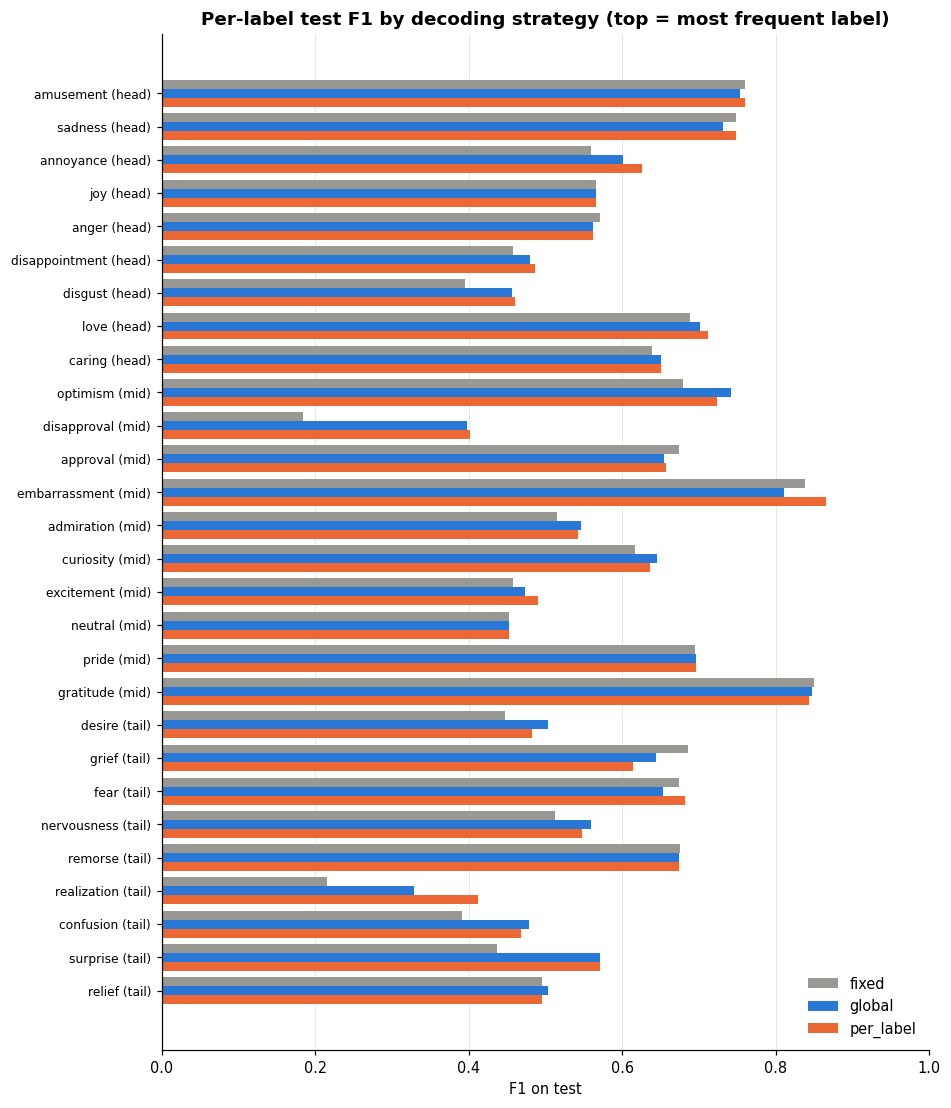

In [8]:
val_pos = Y['val'].sum(0)
per_label = pd.DataFrame({'tier': [TIER_OF[l] for l in LABELS], 'train count': train_count, 'val positives': val_pos,
                          'τc*': THR['per_label']}, index=LABELS)
for s in STRATEGIES:
    per_label[f'val F1 {s}'] = label_f1(Y['val'], PRED[s]['val'])
    per_label[f'test F1 {s}'] = label_f1(Y['test'], PRED[s]['test'])
    per_label[f'ΔF1 {s}'] = per_label[f'val F1 {s}'] - per_label[f'test F1 {s}']
per_label['test gain per_label vs fixed'] = per_label['test F1 per_label'] - per_label['test F1 fixed']
per_label['test gain per_label vs global'] = per_label['test F1 per_label'] - per_label['test F1 global']
per_label = per_label.sort_values('train count', ascending=False)
print('Per-label F1, sorted by train frequency')
save_table(per_label, 'table_per_label_f1')

fig, ax = plt.subplots(figsize=(9, 12))
yy = np.arange(N_LABELS)[::-1]; h = 0.27
for k, s in enumerate(STRATEGIES):
    ax.barh(yy + (1 - k) * h, per_label[f'test F1 {s}'], height=h, color=STRAT_COLORS[s], label=s)
ax.set_yticks(yy); ax.set_yticklabels([f'{l} ({TIER_OF[l]})' for l in per_label.index], fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel('F1 on test'); ax.grid(axis='y', visible=False)
ax.set_title('Per-label test F1 by decoding strategy (top = most frequent label)')
ax.legend(frameon=False, loc='lower right')
save_fig(fig, 'per_label_f1')

## 7. Gains and gaps by frequency tier (tests the hypothesis)

Tier F1 is the mean per-label F1 of the tier's labels. Part 1 of the hypothesis predicts the largest test gain in the
tail; part 2 predicts the largest validation-to-test gap (and excess gap) for `per_label` in the tail.

,labels,val positives (min-max),val fixed,test fixed,ΔF1 fixed,val global,test global,ΔF1 global,val per_label,test per_label,ΔF1 per_label,test gain global vs fixed,excess gap global,test gain per_label vs fixed,excess gap per_label,test gain per_label vs global
tier,,,,,,,,,,,,,,,,
head,9,131-354,0.5972,0.5981,-0.0009,0.6190,0.6113,0.0077,0.6282,0.6189,0.0093,0.0132,0.0086,0.0208,0.0102,0.0076
mid,10,87-137,0.5677,0.5961,-0.0284,0.6044,0.6266,-0.0221,0.6201,0.6309,-0.0108,0.0304,0.0063,0.0347,0.0177,0.0043
tail,9,58-117,0.5026,0.5038,-0.0012,0.5425,0.5462,-0.0038,0.5738,0.5498,0.0239,0.0425,-0.0026,0.0460,0.0251,0.0036


Hypothesis part 1: largest test gain of per_label over fixed is in the tail tier (+0.0460).
Hypothesis part 2: largest excess val-to-test gap for per_label is in the tail tier (+0.0251).


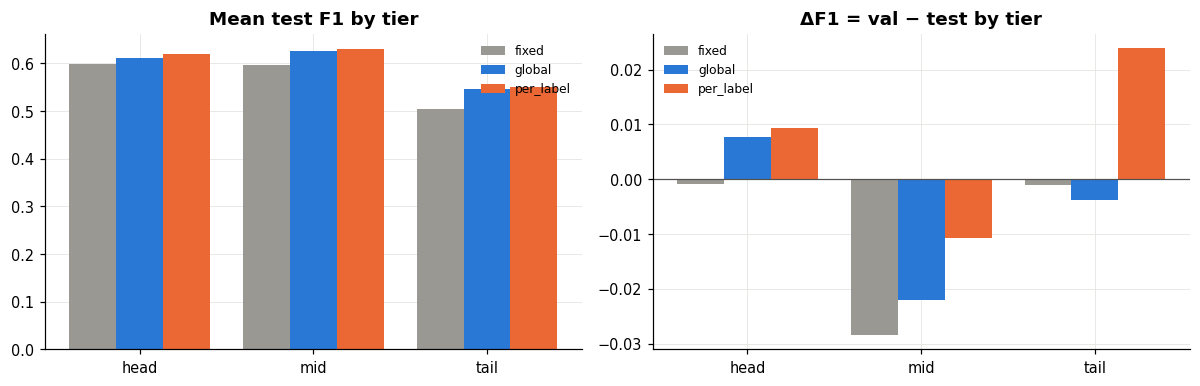

In [9]:
tier_rows = []
for t, idx in TIER_IDX.items():
    r = {'tier': t, 'labels': len(idx), 'val positives (min-max)': f'{val_pos[idx].min()}-{val_pos[idx].max()}'}
    for s in STRATEGIES:
        v, te = label_f1(Y['val'], PRED[s]['val'])[idx].mean(), label_f1(Y['test'], PRED[s]['test'])[idx].mean()
        r.update({f'val {s}': v, f'test {s}': te, f'ΔF1 {s}': v - te})
    for s in ('global', 'per_label'):
        r[f'test gain {s} vs fixed'] = r[f'test {s}'] - r['test fixed']
        r[f'excess gap {s}'] = r[f'ΔF1 {s}'] - r['ΔF1 fixed']
    r['test gain per_label vs global'] = r['test per_label'] - r['test global']
    tier_rows.append(r)
tiers = pd.DataFrame(tier_rows).set_index('tier')
save_table(tiers, 'table_tiers')

best_gain = tiers['test gain per_label vs fixed'].idxmax()
worst_gap = tiers['excess gap per_label'].idxmax()
print(f'Hypothesis part 1: largest test gain of per_label over fixed is in the {best_gain} tier '
      f'(+{tiers.loc[best_gain, "test gain per_label vs fixed"]:.4f}).')
print(f'Hypothesis part 2: largest excess val-to-test gap for per_label is in the {worst_gap} tier '
      f'({tiers.loc[worst_gap, "excess gap per_label"]:+.4f}).')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(TIERS)); w = 0.27
for k, s in enumerate(STRATEGIES):
    axes[0].bar(x + (k - 1) * w, tiers[f'test {s}'], width=w, color=STRAT_COLORS[s], label=s)
    axes[1].bar(x + (k - 1) * w, tiers[f'ΔF1 {s}'], width=w, color=STRAT_COLORS[s], label=s)
for ax, title in zip(axes, ['Mean test F1 by tier', 'ΔF1 = val − test by tier']):
    ax.set_xticks(x); ax.set_xticklabels(list(TIERS)); ax.set_title(title); ax.legend(frameon=False, fontsize=8)
axes[1].axhline(0, color='#52514e', lw=0.8)
fig.tight_layout()
save_fig(fig, 'tiers')

## 8. Breakdown by label cardinality |Y| (test)

n  micro_f1  mean predicted labels  % fewer labels than gold  \
|Y| strategy                                                                    
1   fixed      695    0.5948                 1.2158                    8.6331   
    global     695    0.5399                 1.6863                    2.1583   
    per_label  695    0.5233                 1.8374                    1.7266   
2   fixed      946    0.6005                 1.5381                   47.7801   
    global     946    0.6172                 2.1924                   20.9302   
    per_label  946    0.6202                 2.3668                   15.1163   
3   fixed      360    0.6327                 1.8556                   79.1667   
    global     360    0.6790                 2.5472                   49.7222   
    per_label  360    0.6818                 2.6389                   43.0556   
>=4 fixed       66    0.5639                 2.1212                   95.4545   
    global      66    0.6424                 2.9091                   80.3030   
    per_label   66    0.6300                 3.0000                   77.2727   

               % more labels than gold  % exact set match  % no label  
|Y| strategy                                                           
1   fixed                      25.6115            49.4964      8.6331  
    global                     50.2158            37.4101      2.1583  
    per_label                  55.3957            35.2518      1.7266  
2   fixed                       8.4567            21.8816      6.8710  
    global                     35.3066            19.9789      1.0571  
    per_label                  43.9746            18.8161      0.5285  
3   fixed                       2.5000             9.7222      4.7222  
    global                     14.4444            15.0000      0.2778  
    per_label                  17.2222            15.5556      0.5556  
>=4 fixed                       0.0000             1.5152      3.0303  
    global                      0.0000             6.0606      0.0000  
    per_label                   4.5455             4.5455      0.0000

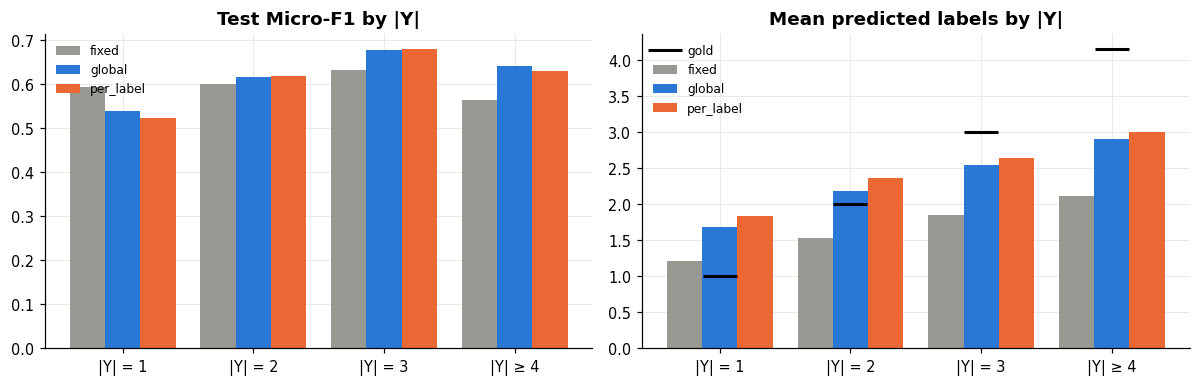

In [10]:
card = Y['test'].sum(1)
BUCKETS = {'1': card == 1, '2': card == 2, '3': card == 3, '>=4': card >= 4}
card_rows = []
for s in STRATEGIES:
    pred = PRED[s]['test']
    n_pred = pred.sum(1)
    for b, m in BUCKETS.items():
        card_rows.append({'strategy': s, '|Y|': b, 'n': int(m.sum()), 'micro_f1': micro_f1(Y['test'][m], pred[m]),
                          'mean predicted labels': n_pred[m].mean(),
                          '% fewer labels than gold': 100 * (n_pred[m] < card[m]).mean(),
                          '% more labels than gold': 100 * (n_pred[m] > card[m]).mean(),
                          '% exact set match': 100 * (pred[m] == Y['test'][m]).all(1).mean(),
                          '% no label': 100 * (n_pred[m] == 0).mean()})
cardinality = pd.DataFrame(card_rows).set_index(['|Y|', 'strategy']).sort_index(level=0, sort_remaining=False)
save_table(cardinality, 'table_cardinality')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(BUCKETS)); w = 0.27
for k, s in enumerate(STRATEGIES):
    sub = cardinality.xs(s, level='strategy').loc[list(BUCKETS)]
    axes[0].bar(x + (k - 1) * w, sub['micro_f1'], width=w, color=STRAT_COLORS[s], label=s)
    axes[1].bar(x + (k - 1) * w, sub['mean predicted labels'], width=w, color=STRAT_COLORS[s], label=s)
axes[1].plot(x, [1, 2, 3, card[card >= 4].mean()], 'k_', ms=22, mew=2, label='gold')
for ax, title in zip(axes, ['Test Micro-F1 by |Y|', 'Mean predicted labels by |Y|']):
    ax.set_xticks(x); ax.set_xticklabels(['|Y| = 1', '|Y| = 2', '|Y| = 3', '|Y| ≥ 4']); ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_fig(fig, 'cardinality')

## 9. Calibrated threshold profile τc\*

`flat width` counts the grid thresholds whose validation F1 is within 0.01 of the label's best F1. A wide flat region
means τc\* is poorly determined by the validation data, which is one way per-label tuning over-fits.

,tier,train count,val positives,τc*,val F1 at 0.5,val F1 at τc*,flat width
amusement,head,2868,327,0.36,0.7273,0.7404,0.19
sadness,head,2785,354,0.46,0.7111,0.7164,0.32
annoyance,head,2662,331,0.20,0.5741,0.6259,0.07
joy,head,1614,168,0.31,0.5489,0.5854,0.05
anger,head,1589,185,0.34,0.5810,0.5922,0.19
disappointment,head,1522,211,0.28,0.4762,0.5122,0.22
disgust,head,1206,164,0.29,0.4231,0.5125,0.02
love,head,1175,148,0.38,0.6937,0.7138,0.12
caring,head,1062,131,0.30,0.6397,0.6549,0.06
optimism,mid,1046,122,0.36,0.6175,0.6967,0.09


Global τ* = 0.31
Spearman ρ(train count, τc*) = 0.181 (p = 0.358)


τc*             flat width            
       mean   min   max       mean   min   max
tier                                          
head  0.324  0.20  0.46      0.138  0.02  0.32
mid   0.322  0.14  0.64      0.147  0.04  0.41
tail  0.288  0.15  0.53      0.054  0.03  0.09

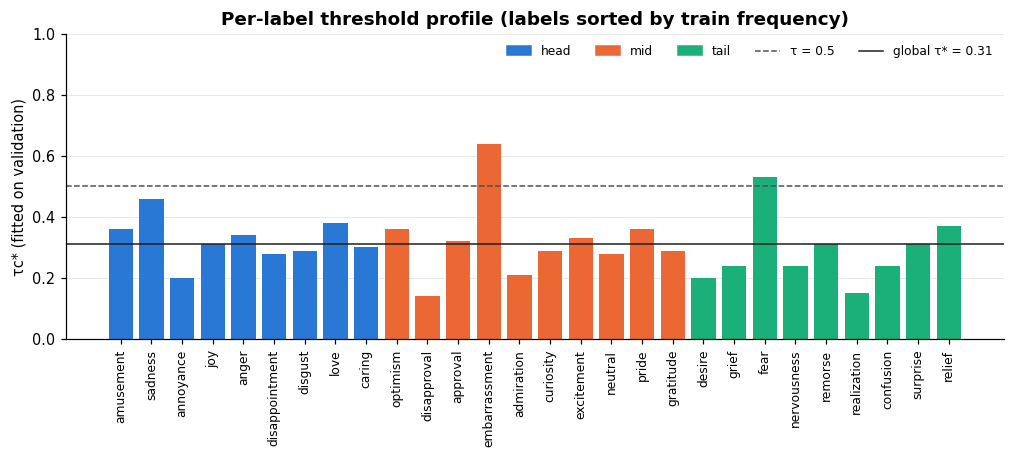

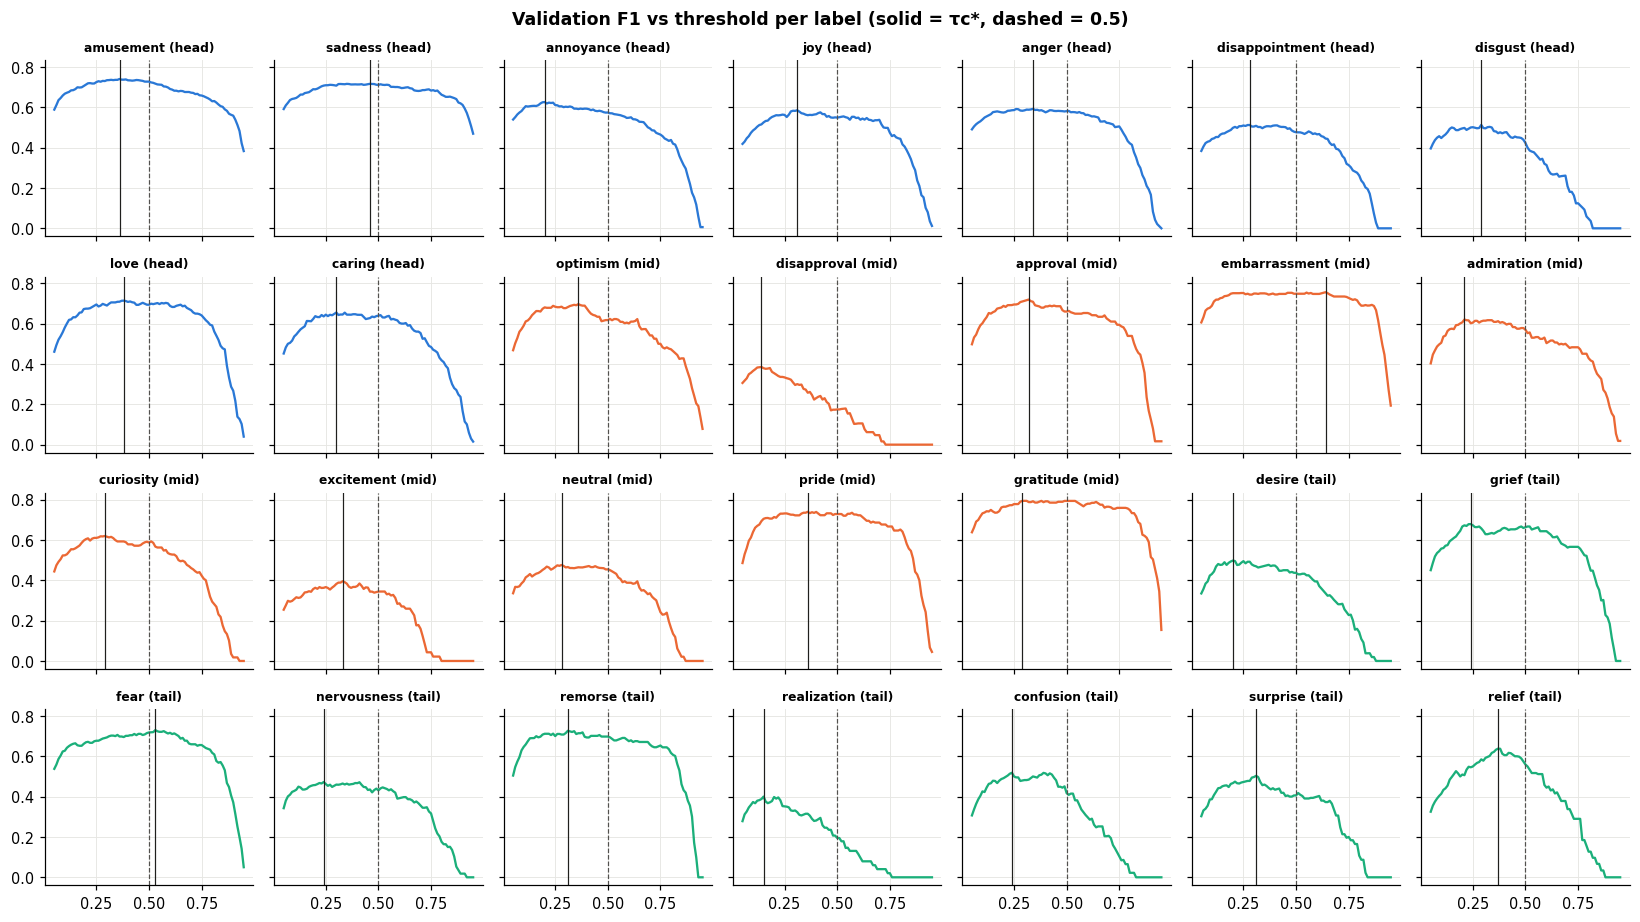

In [11]:
best_val = curves.max(0)
profile = pd.DataFrame({'tier': [TIER_OF[l] for l in LABELS], 'train count': train_count, 'val positives': val_pos,
                        'τc*': THR['per_label'], 'val F1 at 0.5': curves[np.where(TAUS == 0.5)[0][0]],
                        'val F1 at τc*': best_val,
                        'flat width': ((curves >= best_val - 0.01).sum(0) * 0.01).round(2)},
                       index=LABELS).sort_values('train count', ascending=False)
save_table(profile, 'table_threshold_profile')

rho, p_rho = spearmanr(profile['train count'], profile['τc*'])
print(f"Global τ* = {THR['global'][0]:.2f}")
print(f'Spearman ρ(train count, τc*) = {rho:.3f} (p = {p_rho:.3f})')
display(profile.groupby('tier', sort=False)[['τc*', 'flat width']].agg(['mean', 'min', 'max']).round(3))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(range(N_LABELS), profile['τc*'], color=[TIER_COLORS[t] for t in profile['tier']])
ax.axhline(0.5, color='#52514e', ls='--', lw=1, label='τ = 0.5')
ax.axhline(THR['global'][0], color='#1f1f1d', lw=1, label=f"global τ* = {THR['global'][0]:.2f}")
ax.set_xticks(range(N_LABELS)); ax.set_xticklabels(profile.index, rotation=90, fontsize=8)
ax.set_ylabel('τc* (fitted on validation)'); ax.set_ylim(0, 1); ax.grid(axis='x', visible=False)
ax.set_title('Per-label threshold profile (labels sorted by train frequency)')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TIER_COLORS.values()]
ax.legend(handles + ax.get_legend_handles_labels()[0], list(TIER_COLORS) + ax.get_legend_handles_labels()[1],
          frameon=False, ncol=5, fontsize=8)
save_fig(fig, 'threshold_profile')

fig, axes = plt.subplots(4, 7, figsize=(15, 8.5), sharex=True, sharey=True)
for ax, lab in zip(axes.ravel(), profile.index):
    c = LABELS.index(lab)
    ax.plot(TAUS, curves[:, c], color=TIER_COLORS[TIER_OF[lab]])
    ax.axvline(THR['per_label'][c], color='#1f1f1d', lw=0.8); ax.axvline(0.5, color='#52514e', ls='--', lw=0.8)
    ax.set_title(f'{lab} ({TIER_OF[lab]})', fontsize=8)
fig.suptitle('Validation F1 vs threshold per label (solid = τc*, dashed = 0.5)', fontweight='bold')
fig.tight_layout()
save_fig(fig, 'f1_vs_threshold_per_label')

## 10. Error analysis on test (per-label strategy)

### 10.1 What re-thresholding fixes and what it breaks

Per label: false negatives at τ = 0.5 that per-label thresholds recover, and false positives they add.

In [12]:
yt, pf, pp, pt = Y['test'], PRED['fixed']['test'], PRED['per_label']['test'], P['test']
trans = pd.DataFrame({'tier': [TIER_OF[l] for l in LABELS], 'τc*': THR['per_label'], 'support': yt.sum(0),
                      'FN fixed': ((yt == 1) & (pf == 0)).sum(0), 'FN per_label': ((yt == 1) & (pp == 0)).sum(0),
                      'FN recovered': ((yt == 1) & (pf == 0) & (pp == 1)).sum(0),
                      'FP fixed': ((yt == 0) & (pf == 1)).sum(0), 'FP per_label': ((yt == 0) & (pp == 1)).sum(0),
                      'FP added': ((yt == 0) & (pf == 0) & (pp == 1)).sum(0)}, index=LABELS)
trans = trans.sort_values('FN recovered', ascending=False)
save_table(trans, 'table_error_transitions')
print(f"Total: {trans['FN recovered'].sum()} false negatives recovered, {trans['FP added'].sum()} false positives "
      f"added; FN {trans['FN fixed'].sum()} -> {trans['FN per_label'].sum()}, "
      f"FP {trans['FP fixed'].sum()} -> {trans['FP per_label'].sum()}")

,tier,τc*,support,FN fixed,FN per_label,FN recovered,FP fixed,FP per_label,FP added
annoyance,head,0.20,343,169,86,83,105,222,117
disapproval,mid,0.14,112,99,39,60,16,179,163
realization,tail,0.15,95,82,45,37,13,98,85
disgust,head,0.29,141,97,66,31,38,110,72
disappointment,head,0.28,197,113,87,26,86,145,59
confusion,tail,0.24,84,58,37,21,23,70,47
joy,head,0.31,204,99,79,20,62,113,51
admiration,mid,0.21,101,57,37,20,26,71,45
desire,tail,0.20,80,50,31,19,24,74,50
caring,head,0.30,150,59,40,19,44,78,34


Total: 506 false negatives recovered, 1061 false positives added; FN 1809 -> 1304, FP 975 -> 2026


### 10.2 Audit samples: 20 false negatives and 20 false positives

Sampled uniformly at random (seed 42) from all (comment, label) errors of the per-label strategy on test. Fill in
`error_type` and `notes` by hand in the saved CSV; the midterm error types are a good starting list: too few labels,
negative-cluster near-synonym, little context (emoji only / short slang), figurative language or emoji-text
mismatch, debatable gold label.

In [13]:
def names(row):
    return ', '.join(LABELS[i] for i in np.flatnonzero(row)) or '(none)'


def audit_sample(kind):
    mask = (yt == 1) & (pp == 0) if kind == 'FN' else (yt == 0) & (pp == 1)
    r, c = np.nonzero(mask)
    pick = np.random.default_rng(SEED).choice(len(r), size=min(N_AUDIT, len(r)), replace=False)
    rows = []
    for i, j in zip(r[pick], c[pick]):
        rows.append({'sample_id': dfs['test']['id'].iat[i], 'label': LABELS[j], 'tier': TIER_OF[LABELS[j]],
                     'prob': round(pt[i, j], 3), 'τc*': THR['per_label'][j],
                     'also wrong at 0.5': bool(pf[i, j] == pp[i, j]), '|Y|': int(yt[i].sum()),
                     'gold labels': names(yt[i]), 'predicted (per_label)': names(pp[i]),
                     **({'text': dfs['test']['text'].iat[i]} if SHOW_COMMENT_TEXT else {}),
                     'error_type': '', 'notes': ''})
    out = pd.DataFrame(rows)
    out.to_csv(TABLE_DIR / f'rq1_audit_{kind.lower()}.csv', index=False)
    print(f'{kind}: {mask.sum()} errors in total, {len(out)} sampled -> rq1_audit_{kind.lower()}.csv')
    display(out)
    return out


audit_fn = audit_sample('FN')
audit_fp = audit_sample('FP')

FN: 1304 errors in total, 20 sampled -> rq1_audit_fn.csv


,sample_id,label,tier,prob,τc*,also wrong at 0.5,|Y|,gold labels,predicted (per_label),error_type,notes
0,31474,excitement,mid,0.175,0.33,True,3,"excitement, love, optimism","joy, love, optimism, pride",,
1,4795,caring,head,0.075,0.30,True,3,"joy, love, caring","joy, love",,
2,14815,disgust,head,0.191,0.29,True,2,"disgust, anger","sadness, grief, anger",,
3,18541,love,head,0.020,0.38,True,5,"love, caring, gratitude, realization, annoyance","realization, remorse",,
4,you001985,confusion,tail,0.197,0.24,True,1,confusion,"desire, curiosity, sadness",,
5,18983,annoyance,head,0.014,0.20,True,1,annoyance,neutral,,
6,you003603,amusement,head,0.205,0.36,True,2,"amusement, caring","nervousness, annoyance, disapproval",,
7,2,anger,head,0.263,0.34,True,3,"surprise, disgust, anger","disgust, annoyance",,
8,15999,amusement,head,0.020,0.36,True,2,"amusement, optimism",admiration,,
9,19351,surprise,tail,0.167,0.31,True,2,"surprise, fear","fear, nervousness, disgust",,


FP: 2026 errors in total, 20 sampled -> rq1_audit_fp.csv


,sample_id,label,tier,prob,τc*,also wrong at 0.5,|Y|,gold labels,predicted (per_label),error_type,notes
0,6438,joy,head,0.443,0.31,False,1,amusement,"amusement, joy",,
1,you000654,realization,tail,0.341,0.15,False,2,"gratitude, relief","optimism, gratitude, relief, realization",,
2,1581,joy,head,0.735,0.31,True,3,"amusement, love, realization","amusement, joy, love",,
3,red000363,disgust,head,0.602,0.29,True,2,"remorse, embarrassment","fear, nervousness, disgust",,
4,21292,annoyance,head,0.301,0.20,False,1,anger,"anger, annoyance, disapproval",,
5,tik015576,disappointment,head,0.567,0.28,True,1,embarrassment,"disappointment, sadness",,
6,2143,grief,tail,0.276,0.24,False,2,"caring, sadness","disappointment, sadness, grief",,
7,23414,grief,tail,0.390,0.24,False,2,"disappointment, anger","disappointment, sadness, grief",,
8,tik018417,optimism,mid,0.774,0.36,True,3,"love, gratitude, relief","joy, love, optimism, gratitude, relief",,
9,1838,disapproval,mid,0.233,0.14,False,1,curiosity,"anger, annoyance, disapproval",,


### 10.3 High-cardinality comments (|Y| ≥ 4)

In [14]:
hi = np.flatnonzero(card >= 4)
high = pd.DataFrame({'sample_id': dfs['test']['id'].iloc[hi].to_numpy(), '|Y|': card[hi],
                     'gold labels': [names(yt[i]) for i in hi],
                     'predicted fixed': [names(pf[i]) for i in hi], 'correct fixed': (yt[hi] & pf[hi]).sum(1),
                     'predicted per_label': [names(pp[i]) for i in hi], 'correct per_label': (yt[hi] & pp[hi]).sum(1),
                     'wrong per_label': ((1 - yt[hi]) & pp[hi]).sum(1),
                     **({'text': dfs['test']['text'].iloc[hi].to_numpy()} if SHOW_COMMENT_TEXT else {}),
                     'notes': ''})
high.to_csv(TABLE_DIR / 'rq1_audit_high_cardinality.csv', index=False)
print(f'{len(high)} test comments with |Y| >= 4. Gold labels recovered: fixed {high["correct fixed"].sum()}, '
      f'per_label {high["correct per_label"].sum()} of {high["|Y|"].sum()}')
display(high)

66 test comments with |Y| >= 4. Gold labels recovered: fixed 117, per_label 149 of 275


,sample_id,|Y|,gold labels,predicted fixed,correct fixed,predicted per_label,correct per_label,wrong per_label,notes
0,17278,4,"optimism, caring, gratitude, approval","optimism, gratitude, approval",3,"optimism, caring, admiration, gratitude, approval",4,1,
1,17060,5,"joy, love, optimism, caring, gratitude","love, caring, gratitude",3,"joy, love, desire, caring, gratitude",4,1,
2,12474,4,"love, caring, nervousness, sadness",sadness,1,"caring, sadness, grief",2,1,
3,3249,4,"desire, optimism, caring, pride",optimism,1,optimism,1,0,
4,tik014989,4,"joy, optimism, caring, pride","optimism, pride",2,"optimism, pride",2,0,
...,...,...,...,...,...,...,...,...,...
61,1051,4,"amusement, love, desire, admiration","joy, admiration",1,"joy, love, admiration",2,1,
62,16719,4,"amusement, fear, grief, disgust",annoyance,0,"disgust, anger, annoyance",1,2,
63,32516,4,"caring, realization, sadness, grief","desire, caring, disappointment, sadness",2,"desire, caring, disappointment, sadness",2,2,
64,563,5,"surprise, curiosity, confusion, disappointment...","disappointment, annoyance",2,"confusion, disappointment, annoyance, disapproval",3,1,


### 10.4 Systematic confusions and co-occurring pairs

**Confusions:** in the same comment, gold label *a* is missed and label *b* is wrongly predicted.
**Pair recall:** for the 10 most frequent co-occurring pairs in **train** (chosen without test labels), the share of
test comments with both gold labels in which both are predicted.

In [15]:
def confusion_counts(pred):
    return (yt * (1 - pred)).T.astype(int) @ (pred * (1 - yt)).astype(int)    # (a, b): a missed, b wrong


cf, cp = confusion_counts(pf), confusion_counts(pp)
pairs = [(a, b) for a in range(N_LABELS) for b in range(N_LABELS) if a != b]
conf = pd.DataFrame([{'gold missed': LABELS[a], 'predicted instead': LABELS[b], 'fixed': cf[a, b], 'per_label': cp[a, b]}
                     for a, b in pairs])
conf = conf.sort_values('per_label', ascending=False).head(15).reset_index(drop=True)
print('Top-15 confusions under per_label (count of test comments)')
save_table(conf, 'table_confusions')

ytr = Y['train'].astype(int)
co_train = ytr.T @ ytr
top = sorted(((co_train[a, b], a, b) for a in range(N_LABELS) for b in range(a + 1, N_LABELS)), reverse=True)[:10]
pair_rows = []
for cnt, a, b in top:
    both = (yt[:, a] == 1) & (yt[:, b] == 1)
    r = {'pair': f'{LABELS[a]} + {LABELS[b]}', 'train count': cnt, 'test count': int(both.sum())}
    for s in STRATEGIES:
        pr = PRED[s]['test']
        r[f'pair recall {s}'] = ((pr[both, a] == 1) & (pr[both, b] == 1)).mean() if both.any() else np.nan
    pair_rows.append(r)
pair_recall = pd.DataFrame(pair_rows).set_index('pair')
save_table(pair_recall, 'table_pair_recall')

Top-15 confusions under per_label (count of test comments)


,gold missed,predicted instead,fixed,per_label
0,anger,disapproval,3,25
1,anger,annoyance,20,21
2,disgust,disapproval,2,20
3,amusement,annoyance,12,20
4,disgust,annoyance,20,19
5,sadness,annoyance,10,18
6,neutral,annoyance,7,16
7,annoyance,neutral,10,16
8,anger,disappointment,10,15
9,annoyance,disappointment,14,13


,train count,test count,pair recall fixed,pair recall global,pair recall per_label
pair,,,,,
disappointment + sadness,904,127,0.4961,0.5984,0.6220
anger + annoyance,699,84,0.1786,0.4048,0.4405
sadness + grief,620,71,0.7183,0.8028,0.8310
amusement + joy,568,70,0.5143,0.5857,0.5857
annoyance + disapproval,469,59,0.1864,0.4407,0.7119
joy + love,395,42,0.4524,0.6905,0.6905
disgust + anger,379,42,0.3095,0.5476,0.5714
embarrassment + sadness,366,37,0.8378,0.9189,0.8378
excitement + joy,359,46,0.3913,0.5217,0.5000


## 11. Summary

In [16]:
summary = {'model': 'midterm PhoBERT-base-v2 (results/predictions/midterm_phobert_*.csv), backbone not retrained',
           'threshold_grid': [float(TAUS[0]), float(TAUS[-1]), 0.01],
           'global_tau': float(THR['global'][0]),
           'per_label_tau': dict(zip(LABELS, map(float, THR['per_label']))),
           'main_metrics': {f'{s}/{sp}': v for (s, sp), v in main.round(4).to_dict('index').items()},
           'val_test_gap': gap.round(4).to_dict('index'),
           'bootstrap_ci': ci.round(4).to_dict('index'),
           'tiers': tiers.drop(columns='val positives (min-max)').round(4).to_dict('index'),
           'spearman_train_count_vs_tau': {'rho': round(float(rho), 4), 'p': round(float(p_rho), 4)}}
(OUT_DIR / 'rq1_summary.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False))

print('Test Macro-F1:', ', '.join(f"{s} {main.loc[(s, 'test'), 'macro_f1']:.4f}" for s in STRATEGIES))
print('Saved files:')
for f in sorted(OUT_DIR.rglob('rq1_*')):
    print('  ', f.relative_to(OUT_DIR))

Test Macro-F1: fixed 0.5671, global 0.5958, per_label 0.6010
Saved files:
   figures/rq1_cardinality.png
   figures/rq1_f1_vs_threshold_per_label.png
   figures/rq1_per_label_f1.png
   figures/rq1_threshold_profile.png
   figures/rq1_tiers.png
   predictions/rq1_predictions.npz
   predictions/rq1_predictions_test.csv
   predictions/rq1_predictions_val.csv
   rq1_summary.json
   rq1_thresholds.json
   tables/rq1_audit_fn.csv
   tables/rq1_audit_fp.csv
   tables/rq1_audit_high_cardinality.csv
   tables/rq1_table_bootstrap_ci.csv
   tables/rq1_table_cardinality.csv
   tables/rq1_table_confusions.csv
   tables/rq1_table_error_transitions.csv
   tables/rq1_table_main_metrics.csv
   tables/rq1_table_pair_recall.csv
   tables/rq1_table_per_label_f1.csv
   tables/rq1_table_threshold_profile.csv
   tables/rq1_table_tiers.csv
   tables/rq1_table_val_test_gap.csv
